# 07 · Do gas prices and power-station availability help?

A commercial forecaster would feed in the things that actually set GB prices
(docs/candidate-sources.md). Two of them are free, need no sign-up, and keep a record of when each
value was published, so they can be used without peeking:

- **Gas price** (National Gas System Average Price). Gas plants usually set the GB price, so gas
  moves the *level* of the whole day. At D-1 09:00 the latest known gas day is D-3.
- **Power-station availability** (Elexon FOU2T14D): how much of each kind of plant, and how much
  import capacity on the interconnectors, is expected to be available on day D. From this and the
  demand and wind forecasts we derive a **margin**: what could run minus what's needed. A thin
  margin means expensive plants get called on.

Same model, settings, calibration and battery as the `day_ahead` experiment; only the input list
changes. **Decision rule, fixed in advance (as in notebook 03): adopt a group only if it improves
both £ and accuracy on the validation window** (the six months before the test year). The test
year is reported afterwards, not used to decide.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import style

from flexcast.backtest import summarise, valuate
from flexcast.features import AVAILABILITY_COLUMNS, GAS_COLUMNS, build, decision_time_for
from flexcast.history import History
from flexcast.models.base import load_model
from flexcast.models.registry import MODELS
from flexcast.optimise import Battery
from flexcast.storage import Storage

style.use()
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
store = Storage(f"file://{ROOT / 'data'}")
history = History.load(store)
BATTERY = Battery(hourly_blocks=True)
RUNS = {
    "current model": "cand_da_rerun",
    "+ gas": "cand_gas",
    "+ availability": "cand_availability",
    "+ gas + availability": "cand_gas_availability",
}
STRATEGY = "lgbm_calibrated"  # the production forecast (risk-aware alpha was 0 on validation)


def outputs(name: str, kind: str) -> pd.DataFrame:
    return store.read_parquet(f"backtest/experiments/{name}/{kind}.parquet")

## 1. What the new inputs look like

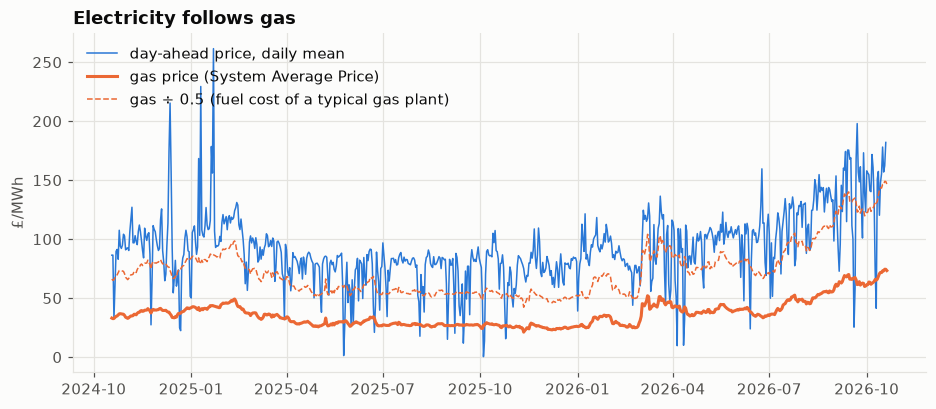

correlation of daily power and gas prices: 0.64


In [2]:
gas = history.gas.set_index(pd.to_datetime(history.gas["gas_day"]))["price"]
da = history.day_ahead.set_index("start_time")["price"]
da_daily = da.groupby(da.index.tz_convert("Europe/London").date).mean()
da_daily.index = pd.to_datetime(da_daily.index)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    da_daily.index, da_daily, color=style.BLUE, linewidth=1, label="day-ahead price, daily mean"
)
ax.plot(gas.index, gas, color=style.ORANGE, label="gas price (System Average Price)")
ax.plot(
    gas.index,
    gas / 0.5,
    color=style.ORANGE,
    linestyle="--",
    linewidth=1,
    label="gas ÷ 0.5 (fuel cost of a typical gas plant)",
)
ax.set(title="Electricity follows gas", ylabel="£/MWh")
ax.legend(loc="upper left")
plt.show()
joined = pd.concat([da_daily.rename("power"), gas.rename("gas")], axis=1).dropna()
print(f"correlation of daily power and gas prices: {joined.corr().iloc[0, 1]:.2f}")

The dashed line is roughly what it costs a gas plant to make a MWh (they turn about half the gas
energy into electricity). Power prices sit near it most days, dipping below when wind and solar
push gas off the system.

The margin, from the availability data, built exactly as the model sees it at D-1 09:00:

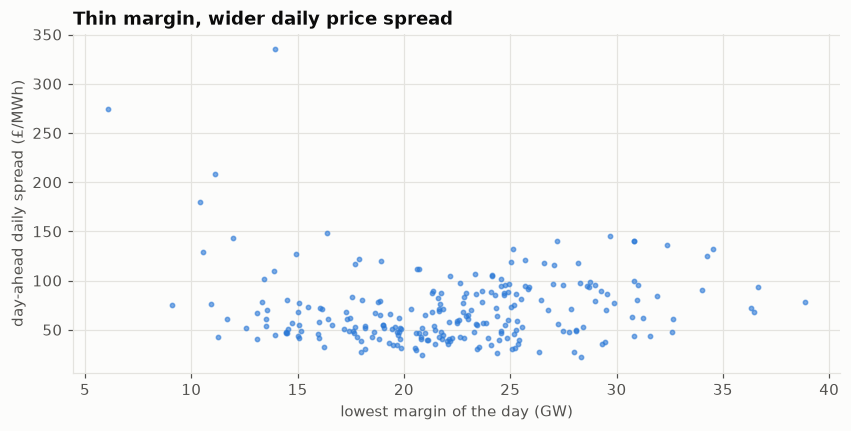

rank correlation, margin vs spread: 0.17


In [3]:
days = sorted(set(history.day_ahead["london_date"]))[14:]
rows = []
for d in days[::3]:  # every third day keeps this quick
    X = build(history, decision_time_for(d), d).X
    actual = history.actual_prices(d, "day_ahead")
    rows.append({"date": d, "margin_min": X["margin"].min(), "spread": actual.max() - actual.min()})
m = pd.DataFrame(rows).dropna()

fig, ax = plt.subplots()
ax.scatter(m["margin_min"] / 1000, m["spread"], s=8, color=style.BLUE, alpha=0.6)
ax.set(
    title="Thin margin, wider daily price spread",
    xlabel="lowest margin of the day (GW)",
    ylabel="day-ahead daily spread (£/MWh)",
)
plt.show()
print(
    f"rank correlation, margin vs spread: {m['margin_min'].corr(m['spread'], method='spearman'):.2f}"
)

## 2. Validation window: the decision

In [4]:
def window_summary(kind: str) -> pd.DataFrame:
    rows = {}
    for label, name in RUNS.items():
        f = outputs(name, kind)
        f = f[f["strategy"].isin([STRATEGY, "perfect"])]
        s = summarise(
            valuate(f, BATTERY) if kind == "validation_forecasts" else outputs(name, "daily")
        )
        rows[label] = s.loc[STRATEGY]
    return pd.DataFrame(rows).T[["gbp_per_year", "pct_of_perfect", "mae", "pinball", "coverage_80"]]


val = window_summary("validation_forecasts")
val.style.format(
    {"coverage_80": "{:.0%}"} | {c: "{:.2f}" for c in val.columns if c != "coverage_80"}
)

,gbp_per_year,pct_of_perfect,mae,pinball,coverage_80
current model,29.89,61.76,8.43,2.70,78%
+ gas,29.65,61.25,8.39,2.69,78%
+ availability,30.04,62.06,8.46,2.72,78%
+ gas + availability,29.78,61.53,8.51,2.75,78%


In [5]:
base = val.loc["current model"]
decisions = {
    label: bool(row.gbp_per_year > base.gbp_per_year and row.mae < base.mae)
    for label, row in val.drop("current model").iterrows()
}
for label, ok in decisions.items():
    row = val.loc[label]
    print(
        f"{label:22s} £/yr {base.gbp_per_year:.2f} → {row.gbp_per_year:.2f}; "
        f"MAE {base.mae:.2f} → {row.mae:.2f}: {'ADOPT' if ok else 'do not adopt'}"
    )

+ gas                  £/yr 29.89 → 29.65; MAE 8.43 → 8.39: do not adopt
+ availability         £/yr 29.89 → 30.04; MAE 8.43 → 8.46: do not adopt
+ gas + availability   £/yr 29.89 → 29.78; MAE 8.43 → 8.51: do not adopt


How much of a difference could be luck? Resample validation days (bootstrap) for the £ difference
against the current model:

In [6]:
def daily_value(name: str) -> pd.Series:
    f = outputs(name, "validation_forecasts")
    d = valuate(f[f["strategy"] == STRATEGY], BATTERY)
    return d.set_index("target_date")["value_gbp"]


rng = np.random.default_rng(0)
base_daily = daily_value(RUNS["current model"])
for label in decisions:
    diff = (daily_value(RUNS[label]) - base_daily).dropna().to_numpy()
    means = [rng.choice(diff, len(diff)).mean() * 365 for _ in range(2000)]
    lo, hi = np.percentile(means, [5, 95])
    print(
        f"{label:22s} £/yr difference {diff.mean() * 365:+.2f}, 90% interval £{lo:+.2f} to £{hi:+.2f}"
    )

+ gas                  £/yr difference -0.25, 90% interval £-1.96 to £+1.40


+ availability         £/yr difference +0.15, 90% interval £-1.52 to £+1.93


+ gas + availability   £/yr difference -0.11, 90% interval £-1.54 to £+1.39


## 3. Test year (reported after the decision)

In [7]:
test = window_summary("forecasts")
test.style.format(
    {"coverage_80": "{:.0%}"} | {c: "{:.2f}" for c in test.columns if c != "coverage_80"}
)

,gbp_per_year,pct_of_perfect,mae,pinball,coverage_80
current model,45.50,65.37,12.43,3.91,78%
+ gas,45.69,65.64,11.82,3.77,79%
+ availability,45.90,65.95,12.87,4.00,78%
+ gas + availability,45.56,65.46,12.00,3.77,79%


## 4. What the model does with the new inputs

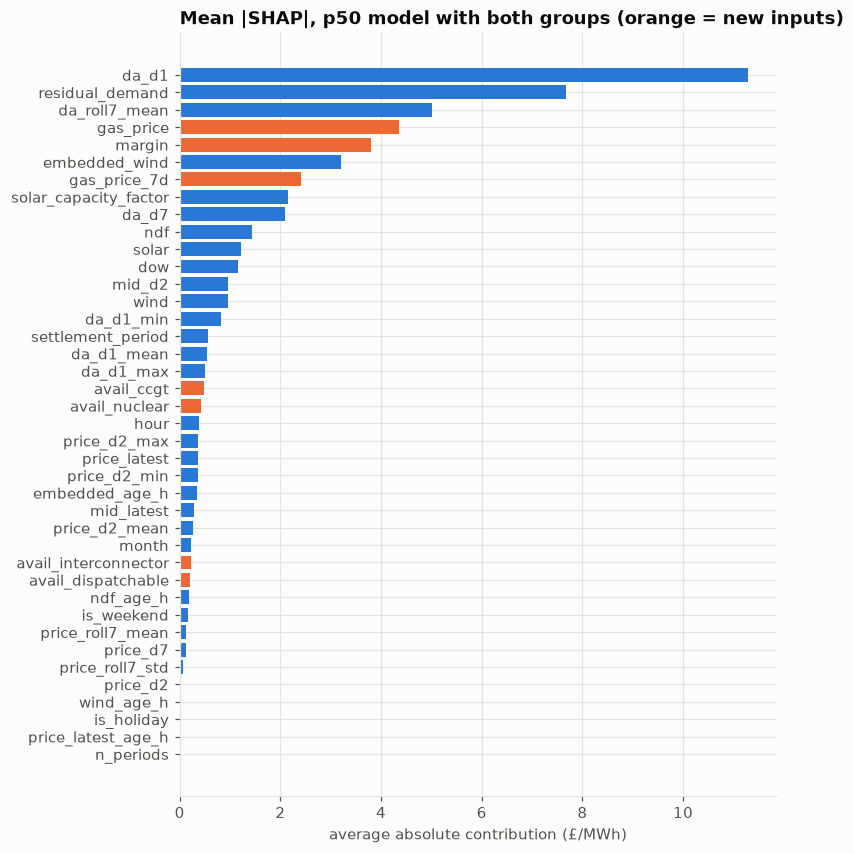

In [8]:
model = load_model(store, f"backtest/experiments/{RUNS['+ gas + availability']}/model", MODELS)
sample = [d for d in days if d.year == 2026][::2]
X = pd.concat([build(history, decision_time_for(d), d).X for d in sample])
contrib = model.boosters["p50"].predict(X[model.features], pred_contrib=True)[:, :-1]
importance = pd.Series(np.abs(contrib).mean(axis=0), index=model.features).sort_values()
new = set(GAS_COLUMNS) | set(AVAILABILITY_COLUMNS)
colors = [style.ORANGE if c in new else style.BLUE for c in importance.index]

fig, ax = plt.subplots(figsize=(7, 9))
ax.barh(importance.index, importance.values, color=colors)
ax.set(
    title="Mean |SHAP|, p50 model with both groups (orange = new inputs)",
    xlabel="average absolute contribution (£/MWh)",
)
plt.show()

## Takeaways

- **Not adopted, by the rule set in advance.** On the validation window neither group improved
  both £ and accuracy, and every £ difference is well inside the bootstrap noise (about ±£1.50 a
  year). The production model is unchanged.
- **Electricity does follow gas** (daily correlation 0.64), and the model leans on gas and margin
  heavily (SHAP: 4th and 5th of 40 inputs). But yesterday's auction prices already carry today's
  gas level, so gas adds little the model didn't know. The battery trades the within-day *shape*,
  which gas barely moves.
- **The validation window couldn't test gas.** Gas sat at ~£25-30/MWh from April to October 2025,
  then nearly tripled during the test year. In the test year gas *did* cut forecast error
  (MAE £12.43 → £11.82, coverage 78% → 79%) but £ stayed flat (£45.50 → £45.69). Adopting it
  because of that would be choosing on the test year: the rule exists to stop exactly that.
- **Availability is weak day to day:** the margin's link to the daily spread is faint (rank
  correlation 0.17). Plant outages matter on rare tight days, which two years of data hold few of.
- **What would test this properly:** a longer history covering a gas shock. The day-ahead price
  (from 2021) and gas price (from 2018) both reach back to the 2022 crisis; the other inputs
  would need backfilling too. Noted as future work.